# Notebook 05 - End-to-End Prediction Pipeline

This notebook demonstrates the **complete inference pipeline** for flood detection on a new SAR image:

1. Load & preprocess a new SAR image
2. Extract latent features using the trained encoder
3. Run Random Forest prediction
4. Visualize the prediction result

## Step 1: Imports & Load Models

In [1]:
import os, sys
# Set project root path cleanly
ROOT_DIR = os.path.abspath('..') if os.path.exists('../config.json') else os.path.abspath('.')
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import rasterio
import joblib
from scipy.ndimage import uniform_filter
from models import ConvAutoencoder
from utils import set_seed, load_config

config = load_config(os.path.join(ROOT_DIR, 'config.json'))
set_seed(config['training']['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TARGET_SIZE = tuple(config['data']['target_size'])

plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

models_dir = os.path.join(ROOT_DIR, 'models')
autoencoder = ConvAutoencoder(dropout_rate=config['model']['dropout_rate']).to(device)
autoencoder.load_state_dict(torch.load(os.path.join(models_dir, 'best_autoencoder.pth'), weights_only=True))
autoencoder.eval()

rf_model = joblib.load(os.path.join(models_dir, 'random_forest.pkl'))
print('Models loaded successfully!')


Models loaded successfully!


## Step 2: Load & Preprocess New SAR Image

In [2]:
S1_DIR = os.path.join(ROOT_DIR, config['data']['s1_dir'])
LABEL_DIR = os.path.join(ROOT_DIR, config['data']['label_dir'])

s1_files = sorted([f for f in os.listdir(S1_DIR) if f.endswith('.tif')])
label_files = sorted([f for f in os.listdir(LABEL_DIR) if f.endswith('.tif')])

test_s1_path   = os.path.join(S1_DIR, s1_files[-1])
test_label_path = os.path.join(LABEL_DIR, label_files[-1])

with rasterio.open(test_s1_path) as src:
    raw_s1 = src.read().astype(np.float32)
with rasterio.open(test_label_path) as src:
    true_label = src.read(1).astype(np.float32)

print(f'Loaded: {s1_files[-1]}')

def preprocess_sar(raw):
    vv = np.nan_to_num(raw[0], nan=-25.0)
    vh = np.nan_to_num(raw[1], nan=-30.0)
    stacked = np.stack([vv, vh])
    filtered = np.stack([uniform_filter(stacked[b], size=3) for b in range(2)])
    vv_norm = (np.clip(filtered[0], -30.0, 0.0) - (-30.0)) / 30.0
    vh_norm = (np.clip(filtered[1], -35.0, -5.0) - (-35.0)) / 30.0
    return np.stack([vv_norm, vh_norm])

preprocessed = preprocess_sar(raw_s1)
print(f'Preprocessed range: VV [{preprocessed[0].min():.3f}, {preprocessed[0].max():.3f}]')


Loaded: Ghana_97516_S1Hand.tif
Preprocessed range: VV [0.086, 0.938]


## Step 3: Feature Extraction & Prediction

In [3]:
img_tensor = torch.tensor(preprocessed, dtype=torch.float32).unsqueeze(0)
img_resized = F.interpolate(img_tensor, size=TARGET_SIZE, mode='bilinear', align_corners=False).to(device)

with torch.no_grad():
    _, latent = autoencoder(img_resized)
    latent_up = F.interpolate(latent, size=TARGET_SIZE, mode='bilinear', align_corners=False)

feats = latent_up.squeeze(0).cpu().numpy().reshape(256, -1).T
y_pred_flat = rf_model.predict(feats)
pred_mask = y_pred_flat.reshape(TARGET_SIZE[0], TARGET_SIZE[1])
pred_proba = rf_model.predict_proba(feats)[:, 1].reshape(TARGET_SIZE[0], TARGET_SIZE[1])

flood_pct = 100 * pred_mask.sum() / pred_mask.size
print(f'Prediction complete! Flood coverage: {flood_pct:.2f}%')


Prediction complete! Flood coverage: 0.01%


## Step 4: Visualize Prediction Result

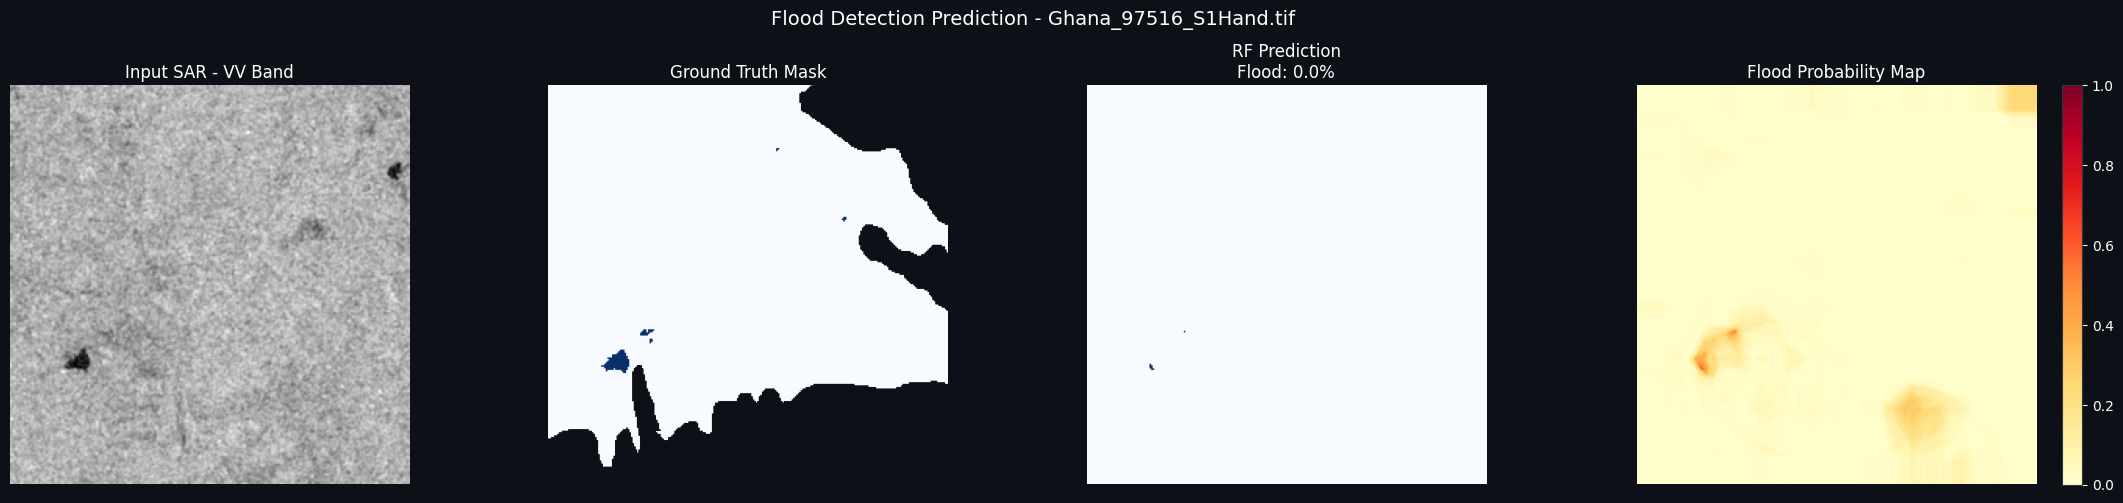

In [4]:
vv_disp = img_resized[0, 0].cpu().numpy()
true_resized = F.interpolate(
    torch.tensor(true_label).unsqueeze(0).unsqueeze(0), size=TARGET_SIZE, mode='nearest'
).squeeze().numpy()
true_display = np.where(true_resized == -1, np.nan, true_resized)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
fig.suptitle(f'Flood Detection Prediction - {s1_files[-1][:25]}', fontsize=14, color='white')

axes[0].imshow(vv_disp, cmap='gray')
axes[0].set_title('Input SAR - VV Band')
axes[0].axis('off')

axes[1].imshow(true_display, cmap='Blues', vmin=0, vmax=1)
axes[1].set_title('Ground Truth Mask')
axes[1].axis('off')

axes[2].imshow(pred_mask, cmap='Blues', vmin=0, vmax=1)
axes[2].set_title(f'RF Prediction\nFlood: {flood_pct:.1f}%')
axes[2].axis('off')

im = axes[3].imshow(pred_proba, cmap='YlOrRd', vmin=0, vmax=1)
axes[3].set_title('Flood Probability Map')
axes[3].axis('off')
plt.colorbar(im, ax=axes[3], fraction=0.046)

plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/prediction_result.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
